In [135]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

In [136]:
# Investment function:

def I(Y, A, B, Y1, Y2):
    I = np.where(Y <= Y1, A, np.where(Y >= Y2, B, (B-A)/(Y2-Y1) * (Y-Y1) + A))
    return I

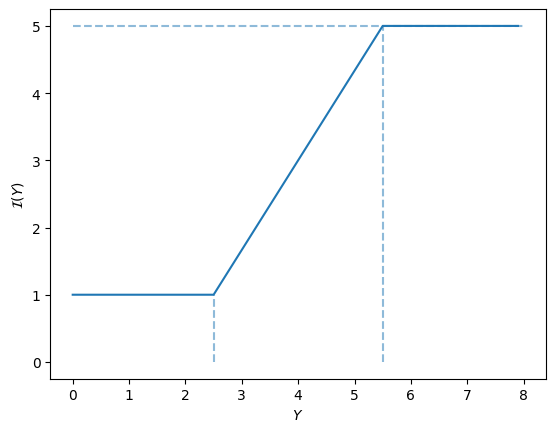

In [137]:
# Plot of the investment function

A = 1
B = 5
Y1 = 2.5
Y2 = 5.5

Y = np.arange(0, 8, 0.1)

I_Y = I(Y, A, B, Y1, Y2)

fig, ax = plt.subplots(1, 1)

ax.plot(Y, I_Y)

ax.hlines(B, 0, 8, ls = "--", alpha = 0.5)

ax.vlines(Y1, 0, 1, ls = "--", alpha = 0.5)
ax.vlines(Y2, 0, 5, ls = "--", alpha = 0.5)

ax.set_xlabel(r"$Y$")
ax.set_ylabel(r"$\mathcal{I}(Y)$")

plt.savefig("../Figures/Piecewise/Investment_function.png")

In [138]:
# Vector field

def vector_field(x, t, alpha, beta, gamma, delta, A, B, Y1, Y2):
    Y = x[0]
    K = x[1]
 
    f_Y = alpha * (I(Y, A, B, Y1, Y2) - beta*K - gamma*Y)
    f_K = I(Y, A, B, Y1, Y2) - beta*K - delta*K
    
    f = np.array((f_Y, f_K))

    return f

In [139]:
# Parameters of the model

beta = 0.8
gamma = 0.5
delta = 0.5

A = 1
B = 2
Y1 = 0.5
Y2 = 2

I_der = (B-A)/(Y2-Y1)

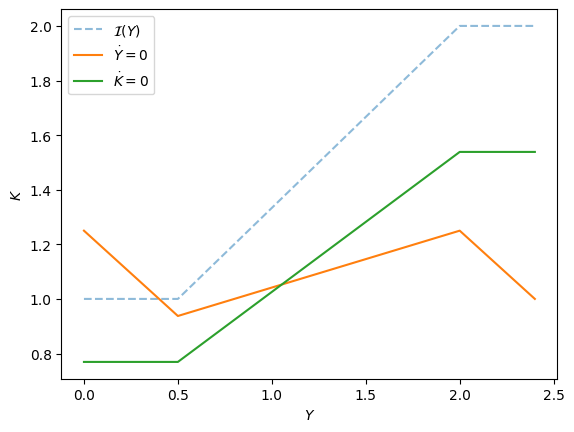

In [140]:
# Null-clines

Y = np.arange(0, 2.5, 0.1)

I_Y = I(Y, A, B, Y1, Y2)

K1 = (I(Y, A, B, Y1, Y2) - gamma * Y) / beta
K2 = I(Y, A, B, Y1, Y2) / (beta + delta)

fig, ax = plt.subplots(1, 1)

ax.plot(Y, I_Y, ls = "--", alpha = 0.5, label = r"$\mathcal{I}(Y)$")
ax.plot(Y, K1, label = r"$\dot{Y} = 0$")
ax.plot(Y, K2, label = r"$\dot{K} = 0$")

ax.set_xlabel(r"$Y$")
ax.set_ylabel(r"$K$")

ax.legend()

plt.savefig("../Figures/Piecewise/Isoclines.png")

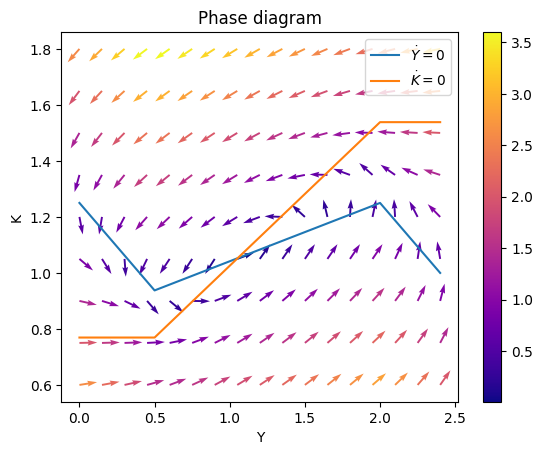

In [141]:
# Vector field and null-clines

alpha = 5

fig, ax = plt.subplots(1, 1)

Y = np.arange(0, 2.5, 0.1)

K1 = (I(Y, A, B, Y1, Y2) - gamma * Y) / beta
K2 = I(Y, A, B, Y1, Y2) / (beta + delta)

ax.plot(Y, K1, label = r"$\dot{Y} = 0$")
ax.plot(Y, K2, label = r"$\dot{K} = 0$")

Y, K =  np.meshgrid(np.arange(0, 2.5, 0.15), np.arange(0.6, 1.8, 0.15))

x = np.array((Y, K))

t = 0
f = vector_field(x, t, alpha, beta, gamma, delta, A, B, Y1, Y2)

f_Y = f[0]
f_K = f[1]

f_norm = np.sqrt(f_Y**2 + f_K**2)

field = ax.quiver(Y, K, f_Y/f_norm, f_K/f_norm, f_norm, cmap = "plasma", angles = "xy")
plt.colorbar(field, ax = ax)

ax.set_title("Phase diagram")
ax.set_xlabel("Y")
ax.set_ylabel("K")

ax.legend()

plt.savefig("../Figures/Piecewise/Vector_field.png")

Y_eq = 1.0526315789473684, K_eq = 1.0526315789473684


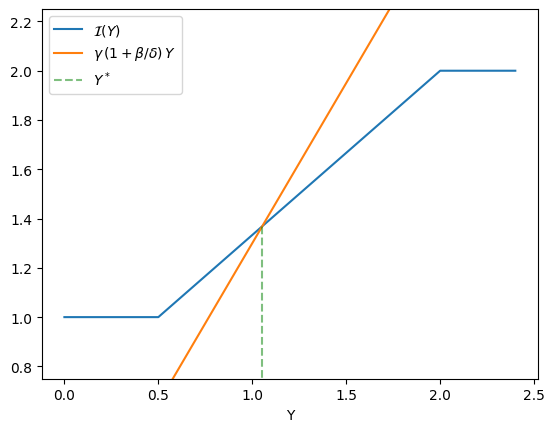

In [142]:
# Equilibrium

Y_eq = (I_der*Y1 - A) / ((B-A)/(Y2-Y1) - gamma * (1 + beta/delta)) 

fig, ax = plt.subplots(1, 1)

Y = np.arange(0, 2.5, 0.1)
f1 = I(Y, A, B, Y1, Y2)
f2 = gamma * (1 + beta/delta) * Y

ax.plot(Y, f1, label = r"$\mathcal{I}(Y)$")
ax.plot(Y, f2, label = r"$\gamma \, (1 + \beta/\delta) \, Y$")

ax.vlines(Y_eq, 0, I(Y_eq, A, B, Y1, Y2), ls = "--", color = "green", alpha = 0.5, label = r"$Y^*$")

ax.set_ylim(0.75, 2.25)
ax.set_xlabel("Y")
ax.legend()

K_eq = gamma/delta * Y_eq

print(f"Y_eq = {Y_eq}, K_eq = {K_eq}")

plt.savefig("../Figures/Piecewise/Equilibrium.png")

alpha s.t. trA = 0: 7.800000000000002


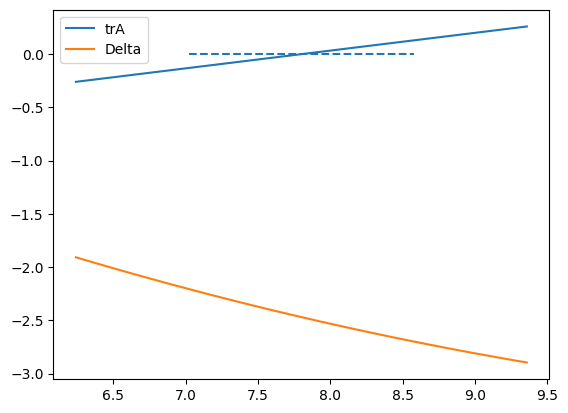

In [143]:
# Around Y_eq, K_eq

def trA(alpha):
    trA = alpha * (I_der - gamma) - (beta + delta)
    return trA

alpha_zero_trA = (beta + delta)/(I_der - gamma)

print(f"alpha s.t. trA = 0: {alpha_zero_trA}")

def detA(alpha):
    detA = -alpha * (delta * I_der - gamma * (beta + delta))
    return detA

def Delta(alpha):
    Delta = (trA(alpha))**2 - detA(alpha)
    return Delta

# plot of trA(alpha) and Delta(alpha) in the range (0.8*alpha_zero_trA, 1.2*alpha_zero_trA)

fig, ax = plt.subplots(1, 1)

alpha = np.linspace(0.8*alpha_zero_trA, 1.2*alpha_zero_trA, 50)

ax.plot(alpha, trA(alpha), label = "trA")
ax.plot(alpha, Delta(alpha), label = "Delta")
ax.hlines(0, 0.9*alpha_zero_trA, 1.1*alpha_zero_trA, ls = "--")

ax.legend()


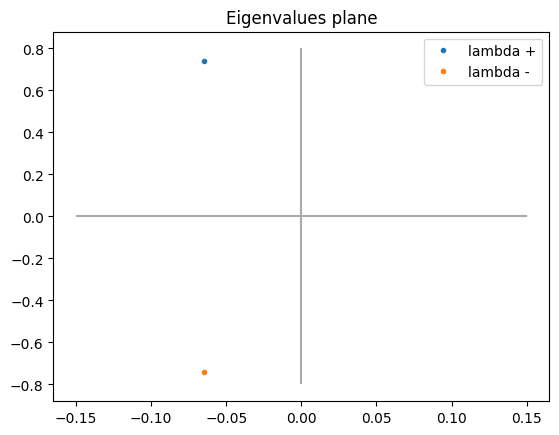

In [144]:
# Negative real part

# draw alpha from uniform distribution and check that Delta(alpha) is negative (complex eigenvalue)
# repeat = True
# while(repeat == True):
#     alpha = np.random.uniform(0.9 * alpha_zero_trA, alpha_zero_trA)
#     if(Delta(alpha) < 0):
#         repeat = False

alpha = 0.9 * alpha_zero_trA

lambda_pls = complex(trA(alpha)/2, np.sqrt(-Delta(alpha))/2)
lambda_min = complex(trA(alpha)/2, -np.sqrt(-Delta(alpha))/2)

# plot of eigenvalues plane
fig, ax = plt.subplots(1, 1)

ax.plot(lambda_pls.real, lambda_pls.imag, ".", label = "lambda +")
ax.plot(lambda_min.real, lambda_min.imag, ".", label = "lambda -")

ax.hlines(0, -0.15, 0.15, color = "darkgrey")
ax.vlines(0, -0.8, 0.8, color = "darkgrey")

ax.set_title("Eigenvalues plane")
ax.legend()

plt.savefig("../Figures/Piecewise/Neg_lambda.png")

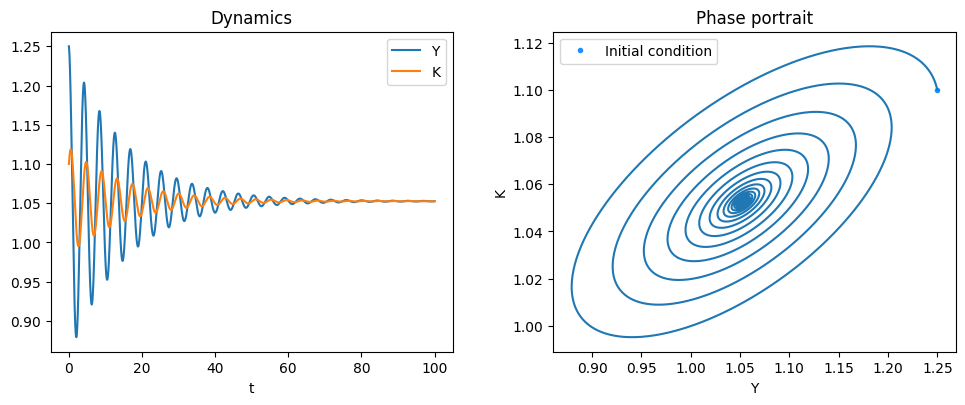

In [145]:
# Dynamics

# initial conditions
x0 = np.array((1.25, 1.1))

# time
T = 100
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(vector_field, x0, t, (alpha, beta, gamma, delta, A, B, Y1, Y2))

Y = x[:, 0]
K = x[:, 1]

# plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 4))
fig.subplots_adjust(left = 0.075, right = 0.98, bottom = 0.1, top = 0.9, wspace = 0.25)

ax1.plot(t, Y, label = "Y")
ax1.plot(t, K, label = "K")

ax1.set_title("Dynamics")
ax1.set_xlabel("t")
ax1.legend()

ax2.plot(x0[0], x0[1], ".", color = "dodgerblue", label = "Initial condition")
ax2.plot(Y, K)
ax2.set_title("Phase portrait")
ax2.set_xlabel("Y")
ax2.set_ylabel("K")

ax2.legend()

plt.savefig("../Figures/Piecewise/Neg_dynamics.png")

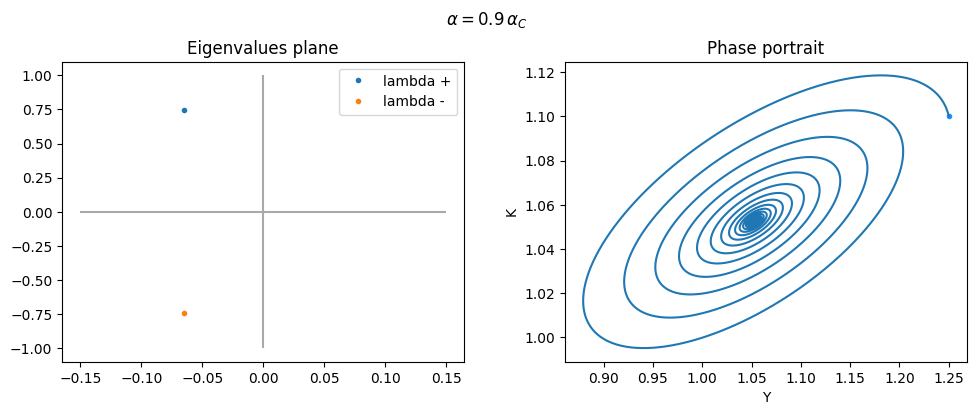

In [146]:
# Plot eigenvalues plane and phase portrait

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 4))
fig.subplots_adjust(left = 0.075, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(r"$\alpha = 0.9 \, \alpha_C$ ")

ax1.plot(lambda_pls.real, lambda_pls.imag, ".", label = "lambda +")
ax1.plot(lambda_min.real, lambda_min.imag, ".", label = "lambda -")

ax1.hlines(0, -0.15, 0.15, color = "darkgrey")
ax1.vlines(0, -1, 1, color = "darkgrey")

ax1.set_title("Eigenvalues plane")
ax1.legend()

ax2.plot(x0[0], x0[1], ".", color = "dodgerblue")
ax2.plot(Y, K)
ax2.set_title("Phase portrait")
ax2.set_xlabel("Y")
ax2.set_ylabel("K")

plt.savefig("../Figures/Piecewise/Neg_eigenvalues_phase_portrait.png")

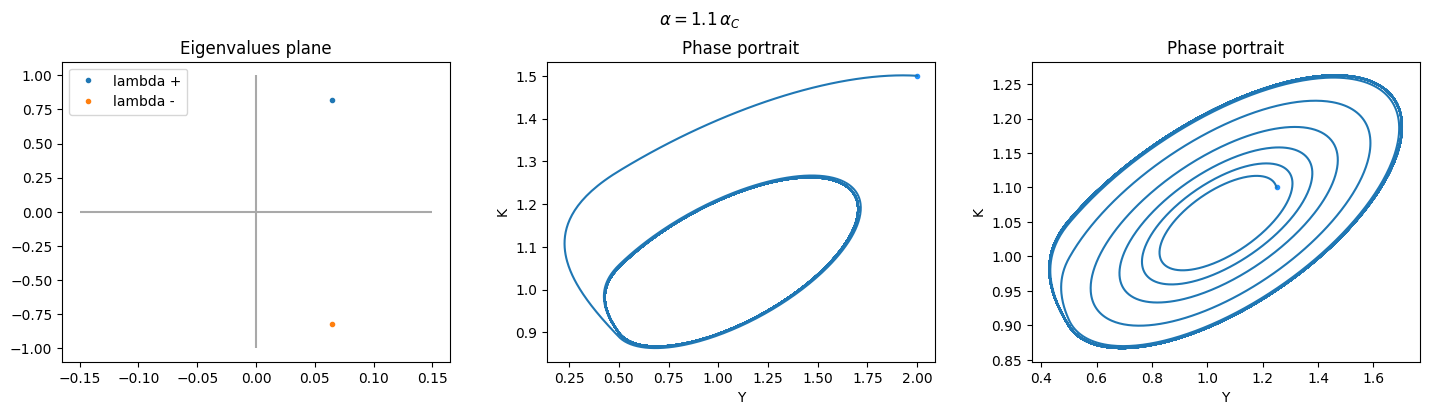

In [147]:
# Positive real part

alpha = 1.1*alpha_zero_trA

# plot eigenvalues plane and phase portrait
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize = (15, 4))
fig.subplots_adjust(left = 0.075, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(r"$\alpha = 1.1 \, \alpha_C$ ")

# eigenvalues
lambda_pls = complex(trA(alpha)/2, np.sqrt(-Delta(alpha))/2)
lambda_min = complex(trA(alpha)/2, -np.sqrt(-Delta(alpha))/2)

ax1.plot(lambda_pls.real, lambda_pls.imag, ".", label = "lambda +")
ax1.plot(lambda_min.real, lambda_min.imag, ".", label = "lambda -")

ax1.hlines(0, -0.15, 0.15, color = "darkgrey")
ax1.vlines(0, -1, 1, color = "darkgrey")

ax1.set_title("Eigenvalues plane")
ax1.legend()


# phase portrait with initial conditions outside the limiting cycle
x0 = np.array((2, 1.5))

T = 100
dt = 0.01
t = np.arange(0, T, dt)

x = odeint(vector_field, x0, t, (alpha, beta, gamma, delta, A, B, Y1, Y2))

Y = x[:, 0]
K = x[:, 1]

ax2.plot(x0[0], x0[1], ".", color = "dodgerblue")
ax2.plot(Y, K)

ax2.set_title("Phase portrait")
ax2.set_xlabel("Y")
ax2.set_ylabel("K")


# Phase portrait with initial conditions inside the limiting cycle
x0 = np.array((1.25, 1.1))

T = 100
dt = 0.01
t = np.arange(0, T, dt)

x = odeint(vector_field, x0, t, (alpha, beta, gamma, delta, A, B, Y1, Y2))

Y = x[:, 0]
K = x[:, 1]

ax3.plot(x0[0], x0[1], ".", color = "dodgerblue")
ax3.plot(Y, K)

ax3.set_title("Phase portrait")
ax3.set_xlabel("Y")
ax3.set_ylabel("K")

plt.savefig("../Figures/Piecewise/Pos_eigenvalues_phase_portrait.png")